# Imports

In [30]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score
from sklearn.metrics import confusion_matrix
from catboost import CatBoostClassifier
import matplotlib.pyplot as plt
import seaborn as sns

# Train

In [31]:
df = pd.read_csv("train.csv")
df.head()

,id,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,...,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,Gender,Customer Type,Type of Travel,Class,satisfaction
0,0,36,694,4,4,4,3,1,4,1,...,4,3,1,0,0.0,Female,Loyal Customer,Personal Travel,Eco,False
1,1,56,651,5,5,5,5,5,4,4,...,5,4,3,0,0.0,Male,Loyal Customer,Business travel,Business,True
2,2,31,1371,3,4,2,5,3,3,3,...,4,5,3,0,0.0,Female,Loyal Customer,Personal Travel,Eco,False
3,3,10,1616,3,5,3,3,3,3,3,...,3,4,3,0,0.0,Male,Loyal Customer,Personal Travel,Eco,False
4,4,23,481,3,4,3,4,5,3,5,...,5,3,5,5,0.0,Female,disloyal Customer,Business travel,Eco,False


In [32]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 699635 entries, 0 to 699634
Data columns (total 23 columns):
 #   Column                             Non-Null Count   Dtype  
---  ------                             --------------   -----  
 0   id                                 699635 non-null  int64  
 1   Age                                699635 non-null  int64  
 2   Flight Distance                    699635 non-null  int64  
 3   Inflight wifi service              699635 non-null  int64  
 4   Departure/Arrival time convenient  699635 non-null  int64  
 5   Ease of Online booking             699635 non-null  int64  
 6   Gate location                      699635 non-null  int64  
 7   Food and drink                     699635 non-null  int64  
 8   Online boarding                    699635 non-null  int64  
 9   Seat comfort                       699635 non-null  int64  
 10  Inflight entertainment             699635 non-null  int64  
 11  On-board service                   699635 non-null

In [33]:
df["satisfaction"].unique()

array([False,  True])

In [34]:
df.describe().round(2)

,id,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes
count,699635.00,699635.0,699635.00,699635.00,699635.00,699635.00,699635.00,699635.00,699635.00,699635.00,699635.00,699635.00,699635.00,699635.00,699635.00,699635.00,699635.00,699343.00
mean,349817.00,39.0,1353.78,2.78,3.16,2.81,3.01,3.27,3.36,3.57,3.45,3.52,3.47,3.81,3.42,3.38,1.18,1.13
std,201967.37,13.8,954.42,1.28,1.48,1.33,1.25,1.30,1.29,1.28,1.31,1.24,1.27,1.08,1.21,1.28,5.98,5.75
min,0.00,7.0,67.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,1.00,0.00,0.00,0.00,0.00
25%,174908.50,27.0,631.00,2.00,2.00,2.00,2.00,2.00,2.00,3.00,2.00,3.00,2.00,3.00,3.00,2.00,0.00,0.00
50%,349817.00,40.0,954.00,3.00,3.00,3.00,3.00,3.00,4.00,4.00,4.00,4.00,4.00,4.00,4.00,4.00,0.00,0.00
75%,524725.50,50.0,1814.00,4.00,4.00,4.00,4.00,4.00,4.00,5.00,5.00,4.00,5.00,5.00,4.00,4.00,0.00,0.00
max,699634.00,85.0,4983.00,5.00,5.00,5.00,5.00,5.00,5.00,5.00,5.00,5.00,5.00,5.00,5.00,5.00,489.00,491.00


In [35]:
df.isna().sum()

id                                     0
Age                                    0
Flight Distance                        0
Inflight wifi service                  0
Departure/Arrival time convenient      0
Ease of Online booking                 0
Gate location                          0
Food and drink                         0
Online boarding                        0
Seat comfort                           0
Inflight entertainment                 0
On-board service                       0
Leg room service                       0
Baggage handling                       0
Checkin service                        0
Cleanliness                            0
Departure Delay in Minutes             0
Arrival Delay in Minutes             292
Gender                                 0
Customer Type                          0
Type of Travel                         0
Class                                  0
satisfaction                           0
dtype: int64

In [36]:
df['Arrival Delay in Minutes'] = df['Arrival Delay in Minutes'].fillna(df['Arrival Delay in Minutes'].median())
df.isna().sum()

id                                   0
Age                                  0
Flight Distance                      0
Inflight wifi service                0
Departure/Arrival time convenient    0
Ease of Online booking               0
Gate location                        0
Food and drink                       0
Online boarding                      0
Seat comfort                         0
Inflight entertainment               0
On-board service                     0
Leg room service                     0
Baggage handling                     0
Checkin service                      0
Cleanliness                          0
Departure Delay in Minutes           0
Arrival Delay in Minutes             0
Gender                               0
Customer Type                        0
Type of Travel                       0
Class                                0
satisfaction                         0
dtype: int64

In [37]:
df = df.rename(columns={'Departure Delay in Minutes' : 'DepDelMin',
                        'Arrival Delay in Minutes' : 'ArDelMin',
                        'Departure/Arrival time convenient' : 'DepArTimeConv'})

In [38]:
df.columns

Index(['id', 'Age', 'Flight Distance', 'Inflight wifi service',
       'DepArTimeConv', 'Ease of Online booking', 'Gate location',
       'Food and drink', 'Online boarding', 'Seat comfort',
       'Inflight entertainment', 'On-board service', 'Leg room service',
       'Baggage handling', 'Checkin service', 'Cleanliness', 'DepDelMin',
       'ArDelMin', 'Gender', 'Customer Type', 'Type of Travel', 'Class',
       'satisfaction'],
      dtype='str')

<Axes: >

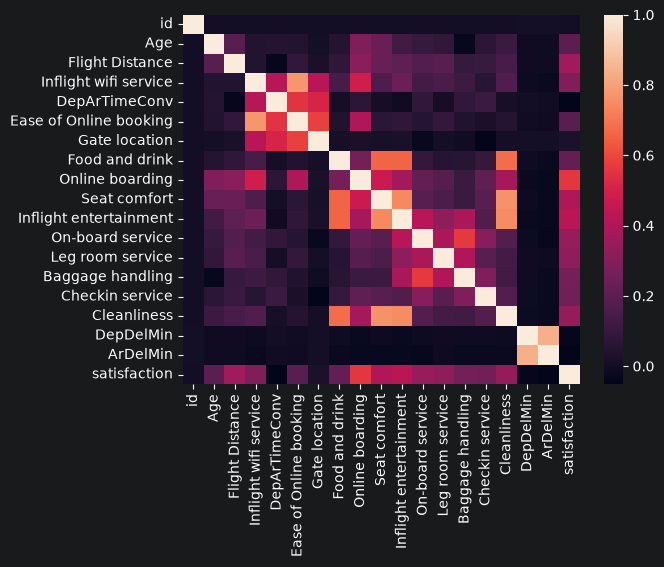

In [39]:
corr_mat = df.corr(method='pearson', numeric_only=True)
sns.heatmap(corr_mat)

In [40]:
df.columns
df.dtypes

id                          int64
Age                         int64
Flight Distance             int64
Inflight wifi service       int64
DepArTimeConv               int64
Ease of Online booking      int64
Gate location               int64
Food and drink              int64
Online boarding             int64
Seat comfort                int64
Inflight entertainment      int64
On-board service            int64
Leg room service            int64
Baggage handling            int64
Checkin service             int64
Cleanliness                 int64
DepDelMin                   int64
ArDelMin                  float64
Gender                        str
Customer Type                 str
Type of Travel                str
Class                         str
satisfaction                 bool
dtype: object

# ML for Train check

In [41]:
# X = df[['Online boarding', 'Seat comfort', 'Inflight entertainment',
#         'On-board service', 'Flight Distance', 'Leg room service',
#         'Class', 'Type of Travel', 'Customer Type',
#         'Inflight wifi service', 'Age', 'Ease of Online booking', 'Gender']]
# y = df['satisfaction']
#
# cat_feature = ['Class', 'Type of Travel', 'Customer Type', 'Gender']
#
# X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.8, random_state=42)
#
# model = CatBoostClassifier(iterations=3000, learning_rate=0.03, depth=6, cat_features=cat_feature, random_seed=42, verbose=200)
# model.fit(X_train, y_train, eval_set=(X_test, y_test), early_stopping_rounds=50)
# predictions = model.predict_proba(X_test)[:, 1]
# # con_mat = confusion_matrix(y_test, predictions)
# roc_auc_score(y_test, predictions)

We can see that we have reached ROC AUC = 0.956 that is pretty good. Best iteration was 2994, and after that our model stoped learning because of the risk of overfitting. I'll use these hyperparameters in my final predictions for test sample

# Test

In [42]:
df_t = pd.read_csv("test.csv")
df.head()

,id,Age,Flight Distance,Inflight wifi service,DepArTimeConv,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,...,Baggage handling,Checkin service,Cleanliness,DepDelMin,ArDelMin,Gender,Customer Type,Type of Travel,Class,satisfaction
0,0,36,694,4,4,4,3,1,4,1,...,4,3,1,0,0.0,Female,Loyal Customer,Personal Travel,Eco,False
1,1,56,651,5,5,5,5,5,4,4,...,5,4,3,0,0.0,Male,Loyal Customer,Business travel,Business,True
2,2,31,1371,3,4,2,5,3,3,3,...,4,5,3,0,0.0,Female,Loyal Customer,Personal Travel,Eco,False
3,3,10,1616,3,5,3,3,3,3,3,...,3,4,3,0,0.0,Male,Loyal Customer,Personal Travel,Eco,False
4,4,23,481,3,4,3,4,5,3,5,...,5,3,5,5,0.0,Female,disloyal Customer,Business travel,Eco,False


In [43]:
df_t.isna().sum()

id                                     0
Age                                    0
Flight Distance                        0
Inflight wifi service                  0
Departure/Arrival time convenient      0
Ease of Online booking                 0
Gate location                          0
Food and drink                         0
Online boarding                        0
Seat comfort                           0
Inflight entertainment                 0
On-board service                       0
Leg room service                       0
Baggage handling                       0
Checkin service                        0
Cleanliness                            0
Departure Delay in Minutes             0
Arrival Delay in Minutes             130
Gender                                 0
Customer Type                          0
Type of Travel                         0
Class                                  0
dtype: int64

In [44]:
df_t['Arrival Delay in Minutes'] = df_t['Arrival Delay in Minutes'].fillna(df['ArDelMin'].median())

In [45]:
df_t = df_t.rename(columns={'Departure Delay in Minutes' : 'DepDelMin',
                        'Arrival Delay in Minutes' : 'ArDelMin',
                        'Departure/Arrival time convenient' : 'DepArTimeConv'})
df_t.columns

Index(['id', 'Age', 'Flight Distance', 'Inflight wifi service',
       'DepArTimeConv', 'Ease of Online booking', 'Gate location',
       'Food and drink', 'Online boarding', 'Seat comfort',
       'Inflight entertainment', 'On-board service', 'Leg room service',
       'Baggage handling', 'Checkin service', 'Cleanliness', 'DepDelMin',
       'ArDelMin', 'Gender', 'Customer Type', 'Type of Travel', 'Class'],
      dtype='str')

# ML for Test check

In [46]:
X_train = df[['Online boarding', 'Seat comfort', 'Inflight entertainment',
        'On-board service', 'Flight Distance', 'Leg room service',
        'Class', 'Type of Travel', 'Customer Type',
        'Inflight wifi service', 'Age', 'Ease of Online booking', 'Gender']]

y_train = df['satisfaction']

X_test = X = df_t[['Online boarding', 'Seat comfort', 'Inflight entertainment',
        'On-board service', 'Flight Distance', 'Leg room service',
        'Class', 'Type of Travel', 'Customer Type',
        'Inflight wifi service', 'Age', 'Ease of Online booking', 'Gender']]

cat_feature = ['Class', 'Type of Travel', 'Customer Type', 'Gender']

model = CatBoostClassifier(iterations=2994, learning_rate=0.03, depth=6, cat_features=cat_feature, random_state=42, verbose=200)
model.fit(X_train, y_train)
prediction = model.predict_proba(X_test)[:, 1]


0:	learn: 0.6630690	total: 77.3ms	remaining: 3m 51s
200:	learn: 0.2488726	total: 10.9s	remaining: 2m 31s
400:	learn: 0.2427105	total: 21.9s	remaining: 2m 21s
600:	learn: 0.2405414	total: 32.8s	remaining: 2m 10s
800:	learn: 0.2392421	total: 43.6s	remaining: 1m 59s
1000:	learn: 0.2382700	total: 54.6s	remaining: 1m 48s
1200:	learn: 0.2374897	total: 1m 10s	remaining: 1m 44s
1400:	learn: 0.2368361	total: 1m 22s	remaining: 1m 33s
1600:	learn: 0.2362418	total: 1m 33s	remaining: 1m 21s
1800:	learn: 0.2357063	total: 1m 45s	remaining: 1m 9s
2000:	learn: 0.2352488	total: 1m 56s	remaining: 57.8s
2200:	learn: 0.2347775	total: 2m 8s	remaining: 46.2s
2400:	learn: 0.2343358	total: 2m 19s	remaining: 34.5s
2600:	learn: 0.2339156	total: 2m 31s	remaining: 22.8s
2800:	learn: 0.2335486	total: 2m 42s	remaining: 11.2s
2993:	learn: 0.2331957	total: 2m 53s	remaining: 0us


In [47]:
submissions = pd.DataFrame({'id' : df_t['id'],
                            'satisfaction' : prediction})
submissions.to_csv('submission1.csv', index=False)